# 03 · Models: Ridge, LightGBM, GRU vs. baselines

Reads results produced by the scripts (does not retrain):
- `python -m src.models.run_cv`   → `experiments/phase3_cv_results.csv`, `phase3_oof.parquet`, `configs/phase3_selected.json`
- `python -m src.models.run_test` → `experiments/phase3_results.csv`, `phase3_test_predictions.parquet`

Protocol: all tuning on 5-fold CV grouped by day; the test set (13 trips with anchors, 6 days) was evaluated **once**,
after the configurations were frozen. Metrics are anchor-weighted (every 100 m prediction point counts once).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
EXP = ROOT / "experiments"
FIG_DIR = ROOT / "figures" / "models"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "text.color": "#0b0b0b", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})
MODELS = ["baseline_global_avg", "baseline_trip_so_far", "ridge", "lgbm", "gru"]
COLOR = {"baseline_global_avg": "#898781", "baseline_trip_so_far": "#c3c2b7",
         "ridge": "#2a78d6", "lgbm": "#1baf7a", "gru": "#eb6834"}
cv_all = pd.read_csv(EXP / "phase3_cv_results.csv")
results = pd.read_csv(EXP / "phase3_results.csv").set_index("model").loc[MODELS]
oof = pd.read_parquet(EXP / "phase3_oof.parquet")
test = pd.read_parquet(EXP / "phase3_test_predictions.parquet")
print(json.dumps(json.loads((EXP / "configs" / "phase3_selected.json").read_text()), indent=1))

{
 "baseline_global_avg": {},
 "baseline_trip_so_far": {},
 "gru": {
  "hidden": 16
 },
 "lgbm": {
  "features": "set2",
  "num_leaves": 3,
  "n_estimators": 150,
  "learning_rate": 0.03
 },
 "ridge": {
  "features": "set2",
  "alpha": 1000.0
 }
}


## 1. Results table (selected configuration per model)

In [2]:
tbl = results[["cv_mae_rate", "cv_rmse_rate", "cv_mae_dte_km", "test_mae_rate", "test_rmse_rate", "test_mae_dte_km"]].copy()
tbl["test_mae_rate ± seed std"] = [f"{v:.3f}" + (f" ± {s:.3f}" if pd.notna(s) else "")
                                   for v, s in zip(results.test_mae_rate, results.get("test_mae_rate_seed_std"))]
tbl.round(3)

,cv_mae_rate,cv_rmse_rate,cv_mae_dte_km,test_mae_rate,test_rmse_rate,test_mae_dte_km,test_mae_rate ± seed std
model,,,,,,,
baseline_global_avg,0.183,0.226,29.782,0.198,0.247,18.380,0.198
baseline_trip_so_far,0.269,0.367,31.756,0.313,0.391,23.462,0.313
ridge,0.139,0.177,23.606,0.192,0.233,19.010,0.192
lgbm,0.139,0.180,23.239,0.210,0.253,19.864,0.210
gru,0.143,0.185,24.217,0.213,0.263,19.234,0.213 ± 0.017


## 2. Tuning: CV score of every configuration

Each dot is one configuration; the feature-set ablation (set1 = brief's list, set2 = + trip history & physics) is
shown side by side. Lines mark the two baselines.

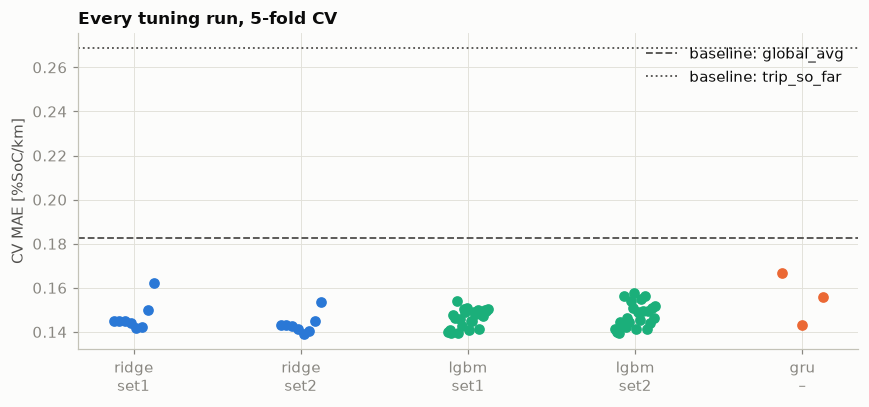

best CV MAE by feature set,set1,set2
model,,
lgbm,0.1395,0.1395
ridge,0.1419,0.1389


In [3]:
main = cv_all[cv_all.tag.isna()].copy()
main["features"] = main.config.map(lambda c: json.loads(c).get("features", "–"))
fig, ax = plt.subplots(figsize=(8, 3.8))
positions = {("ridge", "set1"): 0, ("ridge", "set2"): 1, ("lgbm", "set1"): 2, ("lgbm", "set2"): 3, ("gru", "–"): 4}
for (m, fs), x in positions.items():
    v = main[(main.model == m) & (main.features == fs)].mae_rate
    ax.scatter(np.full(len(v), x) + np.linspace(-0.12, 0.12, len(v)), v, s=36, color=COLOR[m], zorder=3)
for b, ls in [("baseline_global_avg", "--"), ("baseline_trip_so_far", ":")]:
    ax.axhline(main[main.model == b].mae_rate.iat[0], color="#52514e", ls=ls, lw=1.2, label=b.replace("baseline_", "baseline: "))
ax.set_xticks(list(positions.values())); ax.set_xticklabels([f"{m}\n{fs}" for m, fs in positions])
ax.set_ylabel("CV MAE [%SoC/km]"); ax.set_title("Every tuning run, 5-fold CV"); ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "cv_all_configs.png", bbox_inches="tight"); plt.show()

abl = main[main.model.isin(["ridge", "lgbm"])].groupby(["model", "features"]).mae_rate.min().unstack()
abl.columns.name = "best CV MAE by feature set"; abl.round(4)

## 3. Per-fold CV comparison

Does each model beat the global average consistently, or only on average?

In [4]:
per_fold = pd.DataFrame({m: oof.assign(e=(oof[f"pred_{m}"] - oof.rate_next).abs()).groupby("fold").e.mean() for m in MODELS})
display(per_fold.round(3))
for m in ["ridge", "lgbm", "gru"]:
    print(f"{m}: beats the global average in {(per_fold[m] < per_fold.baseline_global_avg).sum()}/5 folds")

,baseline_global_avg,baseline_trip_so_far,ridge,lgbm,gru
fold,,,,,
0,0.218,0.290,0.183,0.181,0.180
1,0.163,0.343,0.114,0.109,0.116
2,0.202,0.291,0.119,0.115,0.110
3,0.148,0.218,0.132,0.128,0.158
4,0.184,0.252,0.139,0.147,0.141


ridge: beats the global average in 5/5 folds
lgbm: beats the global average in 5/5 folds
gru: beats the global average in 4/5 folds


## 4. How certain are these numbers? Bootstrap over trips

Resample whole trips with replacement (4,000 times) and recompute *MAE(model) − MAE(global average)*. Negative = model
better. Trips, not anchors, are resampled because anchors within a trip are strongly correlated.

In [5]:
def boot_diff(df: pd.DataFrame, model: str, n: int = 4000, seed: int = 0) -> tuple[float, float, float]:
    """Mean and 95% CI of anchor-weighted MAE(model) - MAE(global avg), resampling trips."""
    e_m = df.assign(e=(df[f"pred_{model}"] - df.rate_next).abs()).groupby("trip_id").e.agg(["sum", "size"])
    e_b = df.assign(e=(df.pred_baseline_global_avg - df.rate_next).abs()).groupby("trip_id").e.agg(["sum", "size"])
    rng = np.random.default_rng(seed); trips = e_m.index.to_numpy(); d = []
    for _ in range(n):
        s = rng.choice(trips, len(trips), replace=True)
        d.append(e_m.loc[s, "sum"].sum() / e_m.loc[s, "size"].sum() - e_b.loc[s, "sum"].sum() / e_b.loc[s, "size"].sum())
    return float(np.mean(d)), *np.percentile(d, [2.5, 97.5])

rows = []
for name, df in [("CV (out-of-fold)", oof), ("test", test)]:
    for m in ["ridge", "lgbm", "gru"]:
        mean, lo, hi = boot_diff(df, m)
        rows.append({"data": name, "trips": df.trip_id.nunique(), "model": m, "MAE diff vs global avg": mean, "95% CI low": lo, "95% CI high": hi})
ci = pd.DataFrame(rows); display(ci.round(3))

,data,trips,model,MAE diff vs global avg,95% CI low,95% CI high
0,CV (out-of-fold),53,ridge,-0.044,-0.064,-0.026
1,CV (out-of-fold),53,lgbm,-0.044,-0.065,-0.024
2,CV (out-of-fold),53,gru,-0.040,-0.062,-0.019
3,test,13,ridge,-0.008,-0.041,0.018
4,test,13,lgbm,0.009,-0.038,0.043
5,test,13,gru,0.013,-0.031,0.049


## 5. Test set, trip by trip

`bias` = mean(predicted − actual rate); negative = the model expected *less* consumption than happened.
Notes come from Overview.xlsx.

In [6]:
from src.data.load import load_overview
notes = load_overview().set_index("trip_id").note.fillna("").str.strip()
g = test.groupby("trip_id")
trip = pd.DataFrame({"day": g.day.first(), "anchors": g.size(), "share of test": g.size() / len(test),
                     "actual rate": g.rate_next.mean()})
for m in ["baseline_global_avg", "ridge", "lgbm", "gru"]:
    trip[f"bias {m.replace('baseline_', '')}"] = g.apply(lambda s: (s[f"pred_{m}"] - s.rate_next).mean(), include_groups=False)
for m in ["baseline_global_avg", "ridge"]:
    trip[f"MAE {m.replace('baseline_', '')}"] = g.apply(lambda s: (s[f"pred_{m}"] - s.rate_next).abs().mean(), include_groups=False)
trip["note"] = notes.reindex(trip.index).str[:30]
display(trip.round(3))
print(f"ridge beats the global average on {(trip['MAE ridge'] < trip['MAE global_avg']).sum()}/{len(trip)} test trips")
print(f"two longest test trips hold {trip['share of test'].nlargest(2).sum():.0%} of test anchors")

,day,anchors,share of test,actual rate,bias global_avg,bias ridge,bias lgbm,bias gru,MAE global_avg,MAE ridge,note
trip_id,,,,,,,,,,,
TripA23,2019-07-12,24,0.014,0.617,0.090,-0.018,-0.013,-0.009,0.090,0.057,
TripA24,2019-07-12,53,0.030,0.520,0.187,0.176,0.094,0.119,0.193,0.176,
TripA25,2019-07-12,63,0.036,0.749,-0.042,-0.105,-0.165,-0.139,0.198,0.194,
TripA32,2019-07-22,313,0.180,0.718,-0.011,-0.213,-0.173,-0.198,0.247,0.292,
TripB09,2020-01-02,482,0.277,0.789,-0.081,0.015,0.096,0.069,0.167,0.171,"Fast Charging, '+70 kg"
TripB23,2020-01-11,128,0.074,0.983,-0.275,-0.183,-0.210,-0.182,0.318,0.248,+60 kg
TripB24,2020-01-11,34,0.020,0.671,0.036,0.144,0.132,0.078,0.098,0.144,+60 kg
TripB25,2020-01-11,76,0.044,0.803,-0.095,-0.004,-0.020,0.060,0.188,0.176,+70 kg
TripB26,2020-01-11,87,0.050,0.878,-0.171,-0.101,-0.117,0.014,0.184,0.135,


ridge beats the global average on 9/13 test trips
two longest test trips hold 46% of test anchors


### Post-hoc view: every trip weighted equally

*Decided after seeing the test results*, so treat it as a diagnostic, not the headline metric. Anchor-weighting lets the
two longest trips dominate; weighting each trip equally shows whether that drives the result.

In [7]:
trip_weighted = {m: test.assign(e=(test[f"pred_{m}"] - test.rate_next).abs()).groupby("trip_id").e.mean().mean() for m in MODELS}
cv_trip_weighted = {m: oof.assign(e=(oof[f"pred_{m}"] - oof.rate_next).abs()).groupby("trip_id").e.mean().mean() for m in MODELS}
pd.DataFrame({"CV, trip-weighted MAE": cv_trip_weighted, "test, trip-weighted MAE": trip_weighted}).round(3)

,"CV, trip-weighted MAE","test, trip-weighted MAE"
baseline_global_avg,0.176,0.186
baseline_trip_so_far,0.318,0.388
ridge,0.131,0.171
lgbm,0.130,0.178
gru,0.136,0.180


## 6. Predicted vs. actual on the two longest test trips

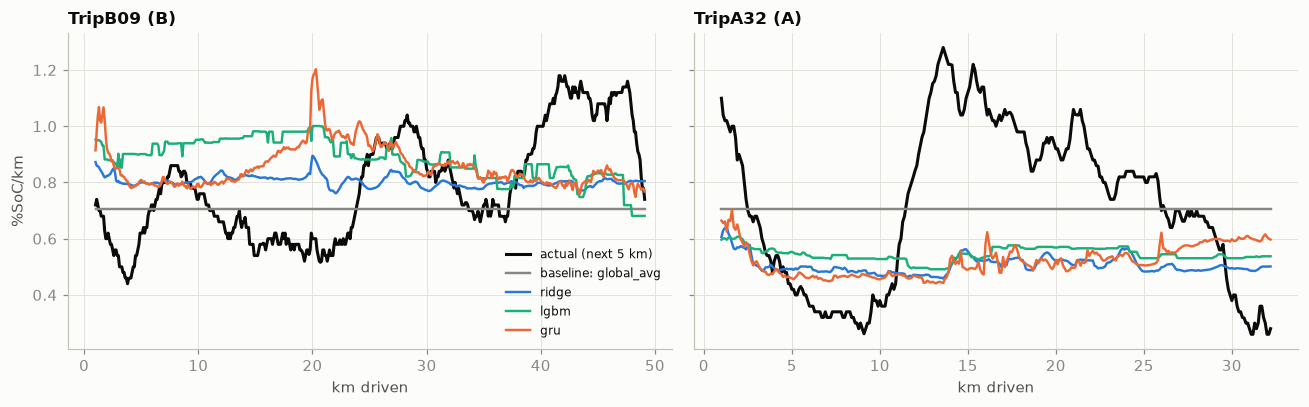

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, tid in zip(axes, trip["anchors"].nlargest(2).index):
    t = test[test.trip_id == tid]
    ax.plot(t.km_in_segment, t.rate_next, color="#0b0b0b", label="actual (next 5 km)")
    for m in ["baseline_global_avg", "ridge", "lgbm", "gru"]:
        ax.plot(t.km_in_segment, t[f"pred_{m}"], color=COLOR[m], lw=1.6, label=m.replace("baseline_", "baseline: "))
    ax.set_title(f"{tid} ({t.series.iat[0]})"); ax.set_xlabel("km driven")
axes[0].set_ylabel("%SoC/km"); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "test_two_longest_trips.png", bbox_inches="tight"); plt.show()